## Experimenting with placing priors on GP nodes from plausible $n(z)$ realizations

### 1. Preparing, plotting, and reconstructing $n(z)$ using GP

In [1]:
# Necessary imports #

# General #

import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy import integrate
from copy import deepcopy
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, ExpSineSquared,
    DotProduct, ConstantKernel as C
)
import sys
import os

import euclidlib as el
import seaborn as sns

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(repo_root)

# Gaussian processes

import matplotlib.pyplot as plt

from binz.run_gp import build_gp_nz 

import matplotlib as mpl 
mpl.rcParams['font.family'] = "serif"
mpl.rcParams['font.serif'] = "Times New Roman"
mpl.rcParams['text.usetex'] = True

In [2]:
# Import and prepare original n(z) distribution #

zs = np.linspace(1e-4, 3, 100)
z, nz = el.phz.redshift_distributions('/home/jipdebuck/nzTabSPV3.fits')

def normalize_dndz(nz_example, z_nz):
    normalized = {}
    for key in nz_example:
        normalized[key] = nz_example[key] / integrate.trapezoid(nz_example[key], z_nz)
    return normalized

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz, z)
dndz_she_norm = normalize_dndz(nz, z)

# Function to resample the normalized dndz
def resample_dndz(nz_example, z_nz, myz):
    my_dndz = np.vstack(list(nz_example.values())) #stacking arrays vertically
    my_dndz_norm = np.zeros([len(nz_example), len(myz)]) #creating an empty array
    for i in range(len(nz_example)):
        my_dndz_norm[i, :] = np.interp(myz, z_nz, my_dndz[i, :]) #interpolating to new myz values
    return my_dndz_norm

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z, zs)

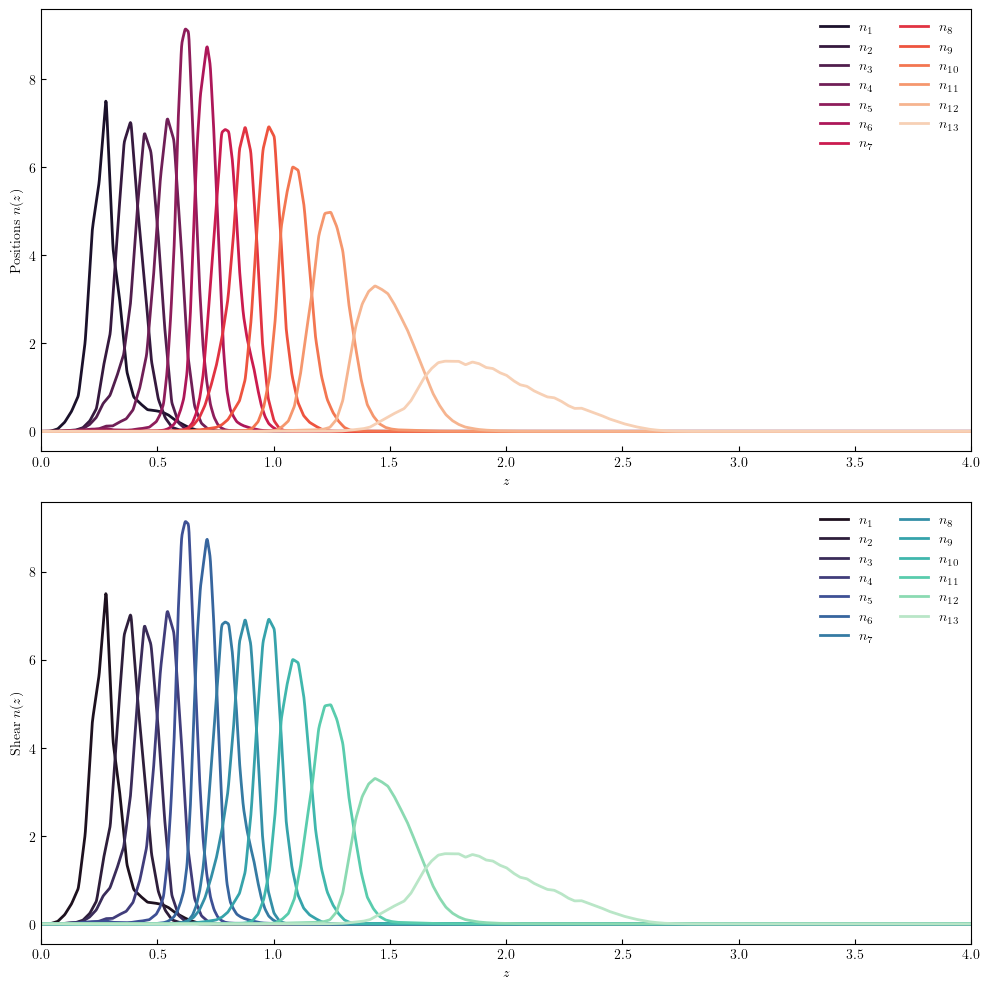

In [3]:
# Plotting of original n(z) distributions #

fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Customize tick parameters for both axes
for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')

# Plot positions n(z)
for i, (key, color) in enumerate(zip(dndz_pos_norm.keys(), sns.color_palette("rocket", len(dndz_pos_norm)))):
    axs[0].plot(z, dndz_pos_norm[key], label=f'$n_{{{i+1}}}$', linewidth=2, color=color)

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs[1].plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

# Set labels and legends
axs[0].set_xlabel(r'$z$')
axs[0].set_ylabel(r'Positions $n(z)$')
axs[0].set_xlim(0, 4)
axs[0].legend(frameon=False, ncol=2)

axs[1].set_xlabel(r'$z$')
axs[1].set_ylabel(r'Shear $n(z)$')
axs[1].set_xlim(0, 4)
axs[1].legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()

In [5]:
# Define parameters for GP reconstruction #

z_meds = []   # positions of median redshift for each bin
n_meds = []   # height of n(z) at median redshift for each bin

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z)
    n_med = nz[np.argmin(np.abs(z - z_med))]
    z_meds.append(z_med)
    n_meds.append(n_med)

corr_len = 0.03                                # correlation length for the GP kernel
z_bounds = (0,3)                              # bounds for the redshift
z_pred = np.linspace(0, 3, 400)       # prediction points for GP
alpha = 1e-8                                  # noise level during fitting 
kernel_class = RBF
nu = 1.5                                      # necessary for Matern only, defines smoothness 
const_value = 0.04                            # amplitude of constant kernel
const_bounds = (1e-4, 1.0)                    # bounds for constant kernel amplitude

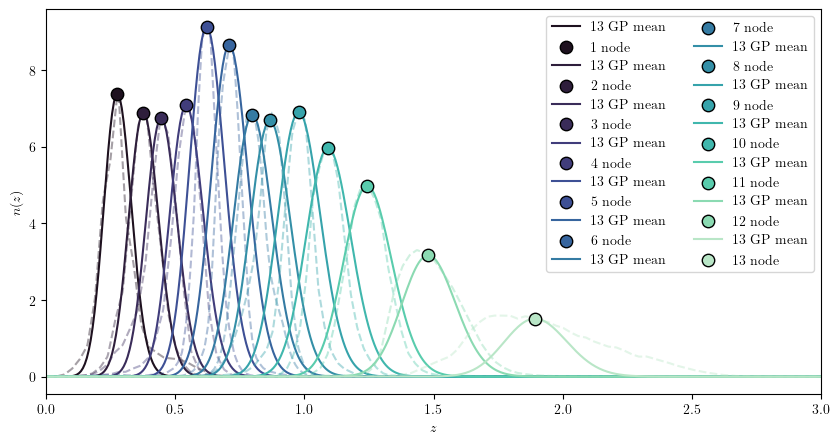

In [6]:
# GP reconstruction and plotting of results #

# Perform GP reconstruction #
priors, predictions = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel_class, nu, const_value, const_bounds)

# Plot GP reconstruction results #
palette = sns.color_palette("mako", 13)
fig, ax = plt.subplots(figsize=(10, 5))

for j, nz in enumerate(n_meds):
    y_pred, y_std = predictions[j]
    X_train, y_train = z_meds[j], n_meds[j]

    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    #ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
    #                color=palette[j], alpha=0.2)

    ax.plot(z, dndz_she_norm[j+1], '--', color=palette[j], alpha=0.4)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{j+1} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(0, 3)
ax.legend(loc="upper right", ncol=2)
plt.show()


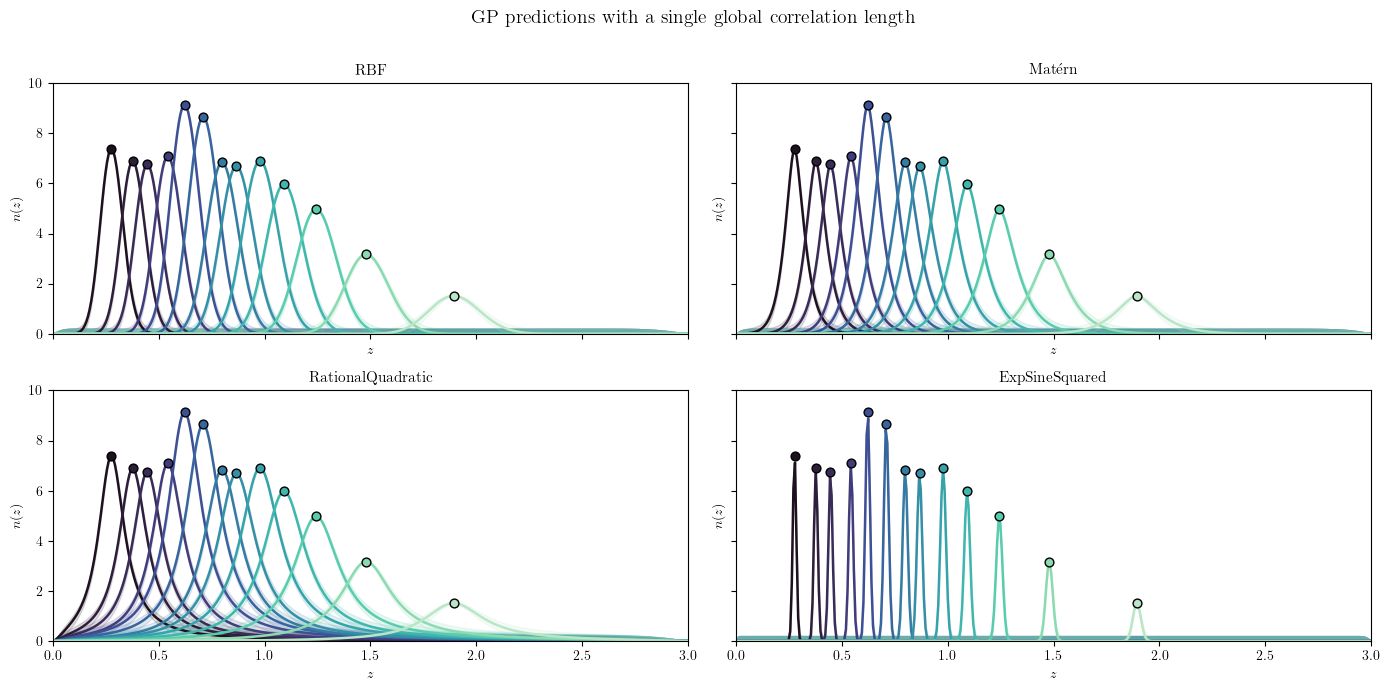

In [7]:
# Results using different kernels #

# Define different kernels #
kernel_dict = {
    "RBF": RBF,
    "Matérn": Matern,
    "RationalQuadratic": RationalQuadratic,
    "ExpSineSquared": ExpSineSquared
}

# Initialize figure for plotting #
n_kernels = len(kernel_dict)
palette = sns.color_palette("mako", len(dndz_she_norm))

fig, axs = plt.subplots(nrows=int(np.ceil(n_kernels/2)), ncols=2,
                        figsize=(14, 3.5 * int(np.ceil(n_kernels/2))),
                        sharex=True, sharey=True)
axs = axs.flatten()

# Compute and plot GP predictions for each kernel #
for ax, (kname, kernel) in zip(axs, kernel_dict.items()):
    
    z_meds = []
    n_meds = []
    for j, (key, nz) in enumerate(dndz_she_norm.items()):
        # --- Compute CDF and median node ---
        cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
        cdf /= cdf[-1]
        z_med = np.interp(0.5, cdf, z)
        n_med = nz[np.argmin(np.abs(z - z_med))]
        z_meds.append(z_med)
        n_meds.append(n_med)

    
    gp_prior, gp_pred = build_gp_nz(n_meds, z_meds, corr_len, z_bounds, z_pred, alpha, kernel, nu, const_value, const_bounds)

    for j, nz in enumerate(n_meds):
        y_pred, y_std = gp_pred[j]
        ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} mean", lw=1.8)
        ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(),
                        (y_pred + y_std).ravel(), color=palette[j], alpha=0.15)
        ax.scatter(z_meds[j], nz, color=palette[j], edgecolor='black', s=40, zorder=3)

        ax.set_title(kname, fontsize=11)
        ax.set_xlim(0, 3)
        ax.set_ylim(0,10)
        ax.set_xlabel(r"$z$")
        ax.set_ylabel(r"$n(z)$")

for ax in axs[len(kernel_dict):]:
    ax.axis("off")

fig.suptitle("GP predictions with a single global correlation length", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


### 2. Guada's work: GP informed by a training node sampled from a prior that is a mean of all possible realiations

In [23]:
# Define the n(z) ensemble and redshift grid to evaluate on 

import numpy as np
from sklearn.decomposition import PCA


def build_pca_nz_prior(z_grid, nz_ensemble, n_components=5, log_eps=1e-12):
    """
    Build a PCA-based Gaussian prior for n(z) from an ensemble of plausible
    redshift distributions.

    Parameters
    ----------
    z_grid : (N_z,) array
        Redshift grid where all n(z) are evaluated.
    nz_ensemble : (N_ens, N_z) array
        Ensemble of plausible n(z) curves.
    n_components : int, optional
        Number of PCA modes to keep (default: 5).
    log_eps : float, optional
        Small number added inside the log to avoid -inf (default: 1e-12).

    Returns
    -------
    prior : dict
        Dictionary containing everything needed to work with the PCA prior:
        - 'z_grid'        : the redshift grid
        - 'pca'           : trained sklearn.decomposition.PCA object
        - 'coeff_mean'    : (k,) mean of PCA coefficients
        - 'coeff_cov'     : (k,k) covariance of PCA coefficients
        - 'n_components'  : number of retained components
        - 'log_eps'       : epsilon used in the log-transform
    """

    z_grid = np.asarray(z_grid)
    nz_ensemble = np.asarray(nz_ensemble)

    # Normalise each n(z) in the ensemble
    norms = np.trapezoid(nz_ensemble, z_grid, axis=1)
    nz_normed = nz_ensemble / norms[:, None]

    # Log-transform to enforce positivity in reconstruction
    f_ensemble = np.log(nz_normed + log_eps)

    # PCA in function space (each f(z) is a row)
    pca = PCA(n_components=n_components)
    coeffs = pca.fit_transform(f_ensemble)   # shape: (N_ens, k)

    # Empirical Gaussian prior on the PCA coefficients
    coeff_mean = np.mean(coeffs, axis=0)               # (k,)
    coeff_cov = np.cov(coeffs, rowvar=False)           # (k, k)

    prior = {
        "z_grid": z_grid,
        "pca": pca,
        "coeff_mean": coeff_mean,
        "coeff_cov": coeff_cov,
        "n_components": n_components,
        "log_eps": log_eps,
    }

    return prior

import numpy as np
from scipy.ndimage import gaussian_filter1d

def generate_bin1_ensemble(
    N_ens=5,
    z_lo=0.001,
    z_hi=6,
    N_z=3001,
    mean_shift_sigma=0.01,
    width_shift_sigma=0.02,
    shape_noise_sigma=0.07,
    smooth_scale=3,
    nz = dndz_she_norm[1]
):
    """
    Generate an ensemble of n(z) realisations for the FIRST bin only:
        z ∈ [0.001, 0.42]
    using small shifts + smooth perturbations.
    """

    # ---------------------------
    # 1. Grid + base bin n(z)
    # ---------------------------
    z = np.linspace(z_lo, z_hi, N_z)
    nz /= np.trapezoid(nz, z)        # ensure norm within [0, 3] part
    nz_bin = nz.copy()               # for first bin, that's it

    # ---------------------------
    # Build ensemble
    # ---------------------------
    ensemble = []

    z_mean = np.trapezoid(z * nz_bin, z)

    for _ in range(N_ens):

        # Mean shift
        dz = np.random.normal(0, mean_shift_sigma) * z_mean
        z_shift = np.clip(z + dz, z_lo, z_hi)

        # Width/stretch shift
        width = 1 + np.random.normal(0, width_shift_sigma)
        z_stretch = z_mean + width * (z_shift - z_mean)
        z_stretch = np.clip(z_stretch, z_lo, z_hi)

        # Smooth random shape fluctuation
        noise = np.random.normal(0, shape_noise_sigma, N_z)
        noise_smooth = gaussian_filter1d(noise, smooth_scale)
        nz_pert = nz_bin * (1 + noise_smooth)
        nz_pert = np.clip(nz_pert, 1e-12, None)

        # Interpolate to shifted grid
        nz_new = np.interp(z, z_stretch, nz_pert, left=0, right=0)

        # Normalise inside the bin
        nz_new /= np.trapezoid(nz_new, z)

        ensemble.append(nz_new)

    return z, np.array(ensemble)

z_ens_list, nz_ensemble_list = zip(*[
    generate_bin1_ensemble(
        N_ens=50, # number of plausible n(z) realizations
        nz=dndz_she_norm[i],  
        N_z=3001 # number of z evaluations
    )
    for i in range(1, 14)
])

print(z_grid)

[1.00000000e-03 2.99966667e-03 4.99933333e-03 ... 5.99600067e+00
 5.99800033e+00 6.00000000e+00]


In [45]:
# Training node sampled from a prior of realizations #

# -----------------------------
# Utilities
# -----------------------------
def x_log1p(z, zmax):
    """Map z to x in [0,1] using log(1+z)."""
    return np.log1p(z) / np.log1p(zmax)

def normalize_nz(z, nz): 
    """
    Normalize the n(z)
    """
    area = np.trapezoid(nz, z)
    area = area if area > 0 else np.finfo(float).tiny
    return nz / area

def kernel_fixed(kernel_class, amp, ell, nu=1.5, amp_bounds=(1e-6, 10.0)):
    """
    Kernel with fixed length-scale ell, fixed (or bounded) amplitude amp.
    We keep optimizer=None, so amp and ell are not learned during GP fitting.
    """
    if kernel_class is Matern:
        return C(amp, amp_bounds) * Matern(length_scale=ell, nu=nu, length_scale_bounds="fixed")
    else:
        return C(amp, amp_bounds) * RBF(length_scale=ell, length_scale_bounds="fixed")


# -----------------------------
# 1) Choose node locations per bin
# -----------------------------
def choose_nodes_from_mean_quantiles(z, nz_mean, quantiles=(0.2, 0.5, 0.8)):
    """
    Choose node locations at given CDF quantiles of the mean n(z).
    """
    nz_mean = normalize_nz(z, np.clip(nz_mean, 0.0, None))
    cdf = np.cumsum((nz_mean[:-1] + nz_mean[1:]) * 0.5 * np.diff(z))
    cdf = np.concatenate([[0.0], cdf])
    cdf = cdf / cdf[-1] if cdf[-1] > 0 else cdf
    z_nodes = np.interp(np.array(quantiles, float), cdf, z)
    return z_nodes


# -----------------------------
# 2) Fit a node-height prior from an ensemble
# -----------------------------
def fit_node_prior_from_ensemble(
    z,
    nz_ensemble,          # (nreal, Nz)
    z_nodes,              # (M,)
    floor_sigma=1e-6,
):
    """
    Returns Gaussian prior params for theta = [n(z_node1),...,n(z_nodeM)]:
        theta ~ N(mu, Sigma)
    computed from the ensemble.
    """
    z = np.asarray(z, float)
    arr = np.asarray(nz_ensemble, float)
    if arr.ndim != 2:
        raise ValueError("nz_ensemble must have shape (nreal, Nz).")
    if arr.shape[1] != z.size:
        raise ValueError("nz_ensemble second dim must match z.")
    z_nodes = np.asarray(z_nodes, float)

    # normalize each realization
    areas = np.trapezoid(arr, z, axis=1)
    areas = np.where(areas > 0, areas, np.finfo(float).tiny)
    arrn = arr / areas[:, None]

    # evaluate node heights by interpolation
    thetas = np.array([np.interp(z_nodes, z, arrn[i]) for i in range(arrn.shape[0])])  # (nreal, M)

    mu = thetas.mean(axis=0)
    Sigma = np.cov(thetas, rowvar=False, ddof=1)
    if thetas.shape[1] == 1:
        Sigma = np.atleast_2d(Sigma)

    # regularize covariance (important if nreal small)
    Sigma = Sigma + (floor_sigma**2) * np.eye(Sigma.shape[0])

    return mu, Sigma # mean and standard deviation of the prior for the node heights 


# -----------------------------
# 3) GP reconstruction FROM NODES (your intended paradigm)
# -----------------------------
def reconstruct_nz_from_nodes_gp(
    z_pred,
    z_nodes,
    theta_nodes,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.concatenate([[zmin], np.asarray(z_nodes, float), [zmax]])
    y_train = np.concatenate([[0.0], np.asarray(theta_nodes, float), [0.0]])

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred,  zmax).reshape(-1, 1)
    print("X_pred:", X_pred.shape)
    print("X_train:", X_train.shape)
    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train)

    if return_std:
        y_pred, y_std = gp.predict(X_pred, return_std=True)
        print("y_pred:", y_pred.shape)
        return y_pred, y_std, gp
    else:
        y_pred = gp.predict(X_pred, return_std=False)
        print("y_pred:", y_pred.shape)
        return y_pred


# -----------------------------
# 4) Build per-bin priors + reconstruction wrapper
# -----------------------------
def build_gp_node_priors_per_bin(
    z,
    nz_ensemble_list,          # list len=nbins, each (nreal, Nz)
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8), # choose 3 nodes by default
    floor_sigma=1e-6,
):
    """
    For each bin:
      - choose node locations from mean n(z) quantiles
      - fit Gaussian prior for node heights from ensemble
    """
    priors = []
    for b, arr in enumerate(nz_ensemble_list):
        arr = np.asarray(arr, float)
        if arr.ndim != 2:
            raise ValueError(f"Bin {b}: expected (nreal, Nz), got {arr.shape}")
        if arr.shape[1] != len(z):
            raise ValueError(f"Bin {b}: Nz mismatch")

        # mean curve for node placement
        areas = np.trapezoid(arr, z, axis=1)
        areas = np.where(areas > 0, areas, np.finfo(float).tiny)
        arrn = arr / areas[:, None]
        nz_mean = arrn.mean(axis=0)

        z_nodes = choose_nodes_from_mean_quantiles(z, nz_mean, quantiles=quantiles)
        mu, Sigma = fit_node_prior_from_ensemble(z, arr, z_nodes, floor_sigma=floor_sigma)

        priors.append({
            "z_nodes": z_nodes,
            "mu": mu,
            "Sigma": Sigma,
        })
    return priors


def logprior_nodes_gaussian(theta_nodes, mu, Sigma):
    """
    Log N(theta_nodes | mu, Sigma)
    """
    th = np.asarray(theta_nodes, float).reshape(-1)
    mu = np.asarray(mu, float).reshape(-1)
    Sigma = np.asarray(Sigma, float)

    # stable solve via Cholesky
    L = np.linalg.cholesky(Sigma)
    y = np.linalg.solve(L, th - mu)
    lp = -0.5 * (y @ y) - np.sum(np.log(np.diag(L))) - 0.5 * th.size * np.log(2*np.pi)
    return float(lp)


def reconstruct_all_bins(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out


# Inputs you already have:
# z_grid: (Nz,) grid
# nz_ensemble_list: list len=13, each (nreal, Nz)

priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)

rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)

X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)
X_pred: (3001, 1)
X_train: (5, 1)
y_pred: (3001,)


Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

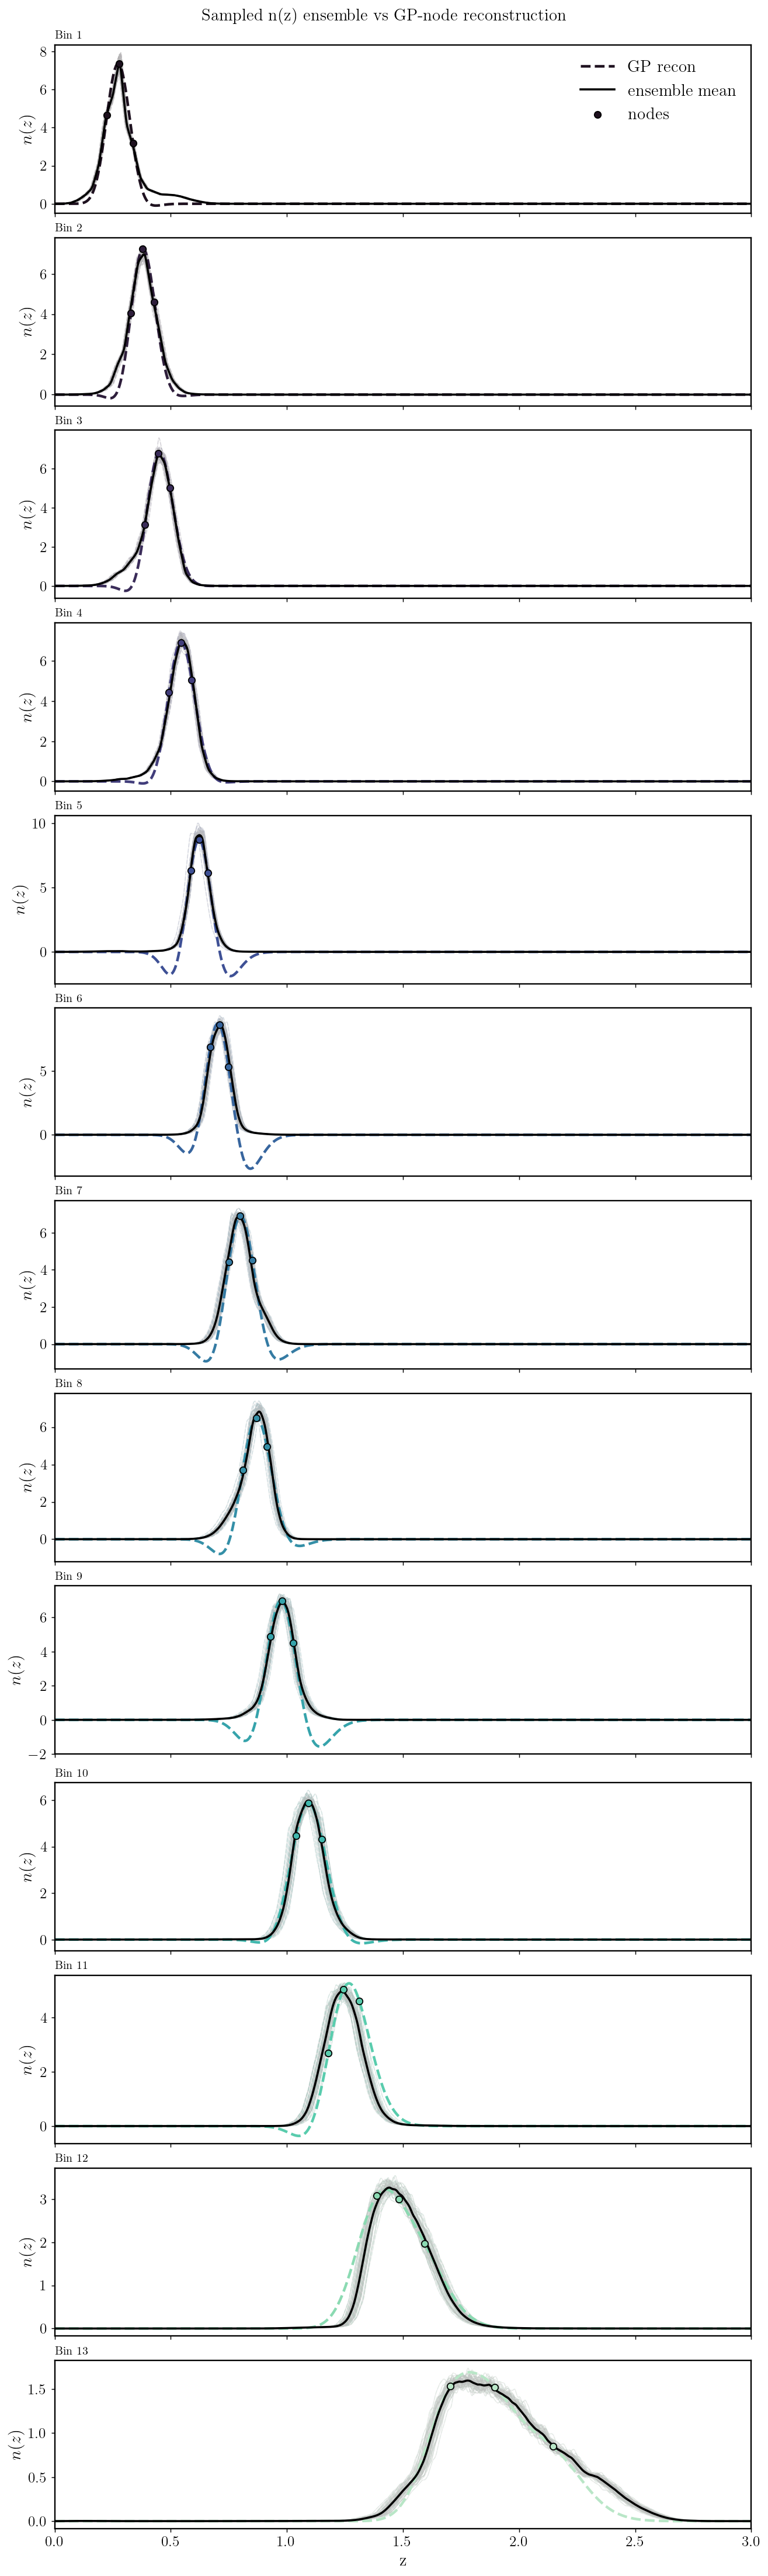

In [22]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")

    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)

# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)
#plt.savefig("/home/jipdebuck/plots/new_reconst.png", dpi=600)

### 3. Enforcing positivity by window function

In [ ]:
# Redefining the way we reconstruct n(z) to enforce positivity # 

def window_func(x):
    """
    Window function to ensure positivity.
    The form of this function is up to the user.
    """
    return x*(1-x)

def reconstruct_nz_from_nodes_gp_pos(
    z_pred,
    z_nodes,
    theta_nodes,
    window,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- set 0 for interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,          # <-- optional like your example
):
    """
    This is the "inferred by the nodes" GP:
      Train on (zmin,0), (z_nodes, theta_nodes), (zmax,0).
      Predict on z_pred.

    IMPORTANT:
    - Do NOT clip/renormalize here if you want the GP mean to pass through nodes.
    - If you need positivity/normalization, do it in the node parameterization
      (e.g., sample log-theta) or use a log-GP model.
    """
    zmin, zmax = z_bounds
    z_pred = np.asarray(z_pred, float)

    # training data (anchors)
    z_train = np.asarray(z_nodes, float)
    y_train = np.asarray(theta_nodes, float)

    X_train = x_log1p(z_train, zmax).reshape(-1, 1)
    X_pred  = x_log1p(z_pred, zmax).reshape(-1, 1)
    print("X_pred:", X_pred.shape)
    print("X_train:", X_train.shape)
    w_pred = window(X_pred.ravel())

    # applying window function
    w_train = window(X_train.ravel())
    y_train_log = np.log(y_train/w_train)

    kernel = kernel_fixed(kernel_class, amp=amp, ell=corr_len, nu=nu, amp_bounds=(1e-6, 10.0))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        optimizer=None,
        normalize_y=False,
        alpha=float(alpha),
        copy_X_train=False,
        random_state=0,
    )
    gp.fit(X_train, y_train_log)

    if return_std:
        y_pred_log, y_std = gp.predict(X_pred, return_std=True)
        y_pred = w_pred*np.exp(y_pred_log)
        return y_pred, y_std, gp
    else:
        y_pred_log = gp.predict(X_pred, return_std=False)
        y_pred = w_pred*np.exp(y_pred_log)
        return y_pred
    
def reconstruct_all_bins_pos(
    z_pred,
    priors,
    theta_all_bins,            # list of arrays, each shape (M,)
    window,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,                 # <-- use 0.0 if you want interpolation
    kernel_class=RBF,
    nu=1.5,
    return_std=False,
):
    """
    Decode all bins at once: returns list of n_b(z_pred).
    If return_std=True, returns list of (mean,std) per bin.
    """
    out = []
    for b, pb in enumerate(priors):
        if return_std:
            mean, std, _ = reconstruct_nz_from_nodes_gp_pos(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                window=window,
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=True,
            )
            out.append((mean, std))
        else:
            nz = reconstruct_nz_from_nodes_gp_pos(
                z_pred=z_pred,
                z_nodes=pb["z_nodes"],
                theta_nodes=theta_all_bins[b],
                window=window,
                z_bounds=z_bounds,
                corr_len=corr_len,
                amp=amp,
                alpha=alpha,
                kernel_class=kernel_class,
                nu=nu,
                return_std=False,
            )
            out.append(nz)
    return out
    
priors = build_gp_node_priors_per_bin(
    z=z_grid,
    nz_ensemble_list=nz_ensemble_list,
    z_bounds=(0.0, 3.0),
    quantiles=(0.2, 0.5, 0.8),  # 3 nodes per bin (tune to 2–5)
)
rng = np.random.default_rng(42)

theta_all_bins = []
for b, pb in enumerate(priors):
    mu = pb["mu"]        # shape (M,)
    Sigma = pb["Sigma"]  # shape (M, M)
    theta_b = rng.multivariate_normal(mu, Sigma)
    theta_all_bins.append(theta_b)

nz_recon = reconstruct_all_bins_pos(
    z_pred=z_grid,
    priors=priors,
    theta_all_bins=theta_all_bins,
    window=window_func,
    z_bounds=(0.0, 3.0),
    corr_len=0.03,
    amp=0.04,
    alpha=0.0,           # <-- crucial for interpolation
)


[0.2260341  0.27670891 0.33764893]
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)
X_pred: (3001, 1)
X_train: (3, 1)


Text(0.5, 0.98, 'Sampled n(z) ensemble vs GP-node reconstruction')

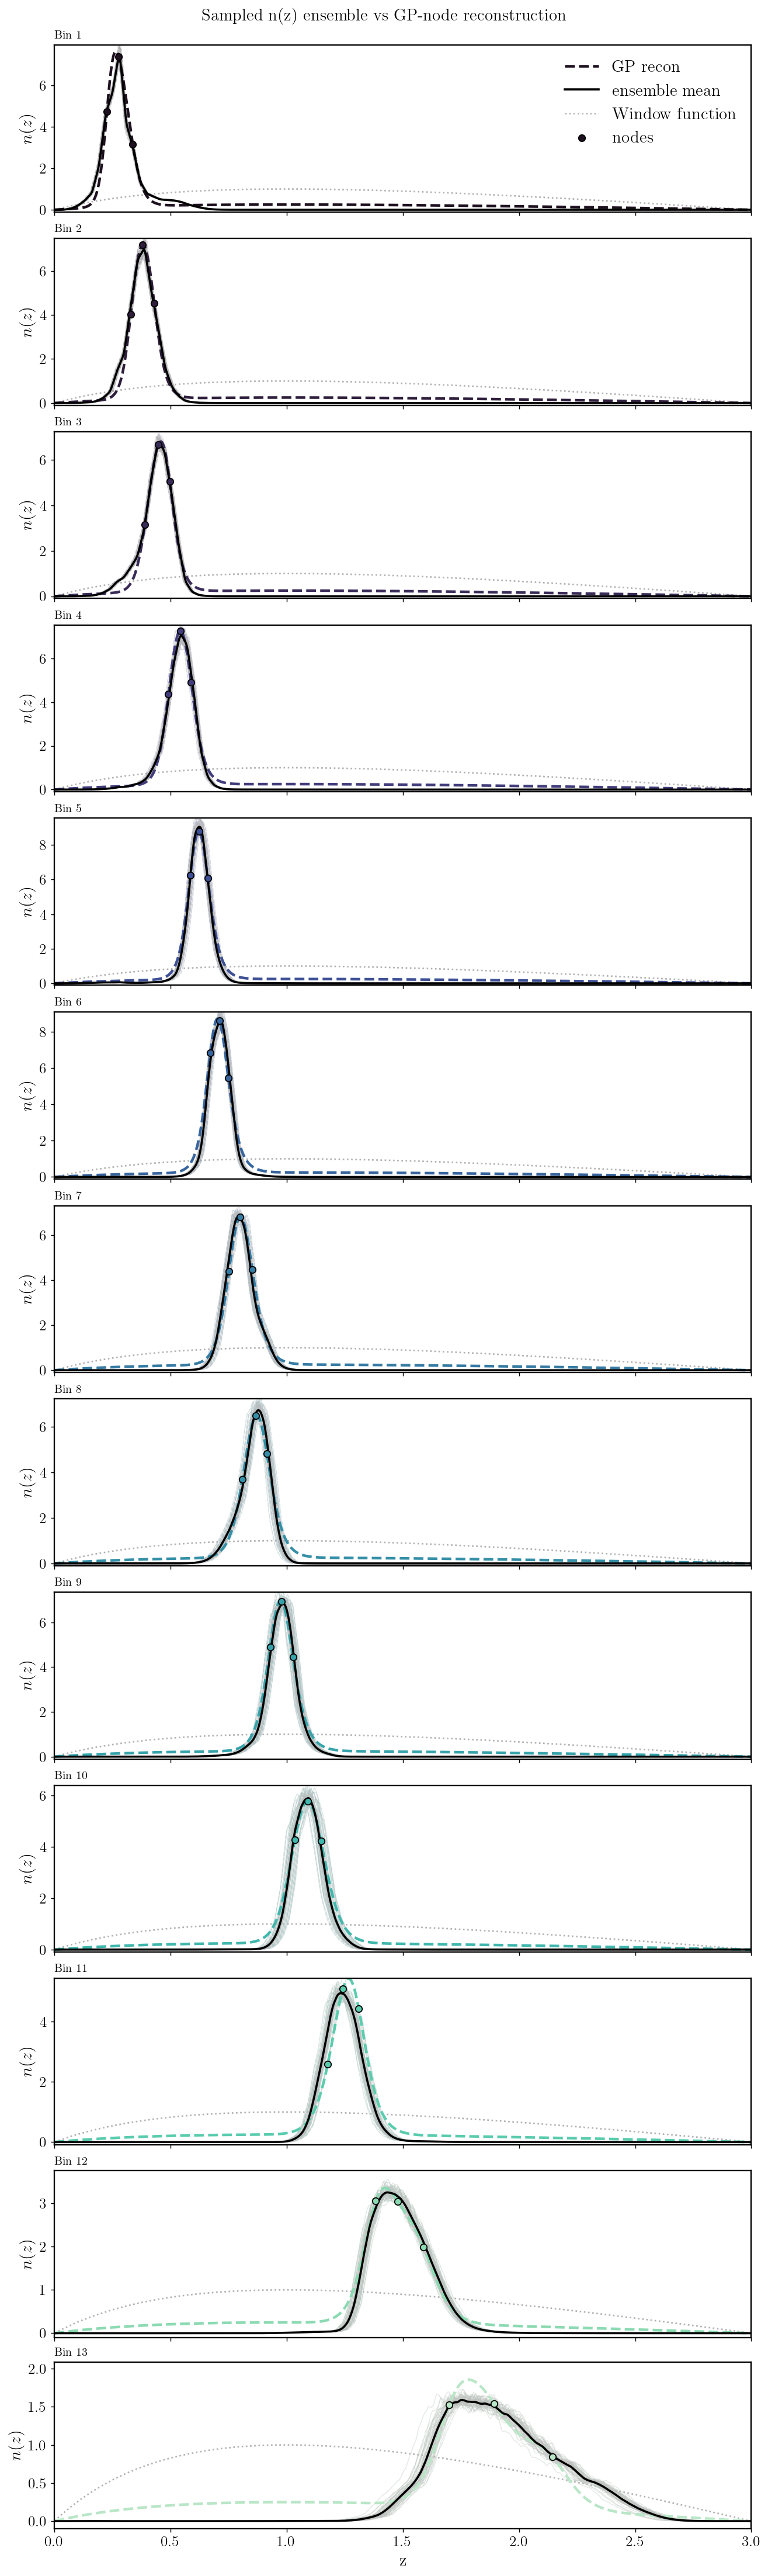

In [54]:
palette = sns.color_palette("mako", len(priors))

n_bins = len(priors)

x_grid = x_log1p(z_grid, 3)
w_grid = window_func(x_grid)
w_grid_norm = w_grid/np.max(w_grid)

fig, axes = plt.subplots(
    n_bins, 1,
    figsize=(10, 2.6 * n_bins),
    sharex=True,
    constrained_layout=True
)

for b in range(n_bins):
    ax = axes[b]

    arr = nz_ensemble_list[b]

    # --- Original ensemble (thin dashed)
    for i in range(arr.shape[0]):
        nz_i = arr[i] / np.trapezoid(arr[i], z_grid)
        ax.plot(z_grid, nz_i,
                color=palette[b],
                alpha=0.15, lw=1, ls="--")
        

    # --- Ensemble curves (solid, translucent)
    for i in range(arr.shape[0]):
        ax.plot(z_grid,
                arr[i] / np.trapezoid(arr[i], z_grid),
                color="silver", alpha=0.3, lw=0.8)

    # --- GP reconstruction
    ax.plot(z_grid, nz_recon[b],
            color=palette[b], ls='--', lw=2.5, label="GP recon")

    # --- Ensemble mean
    nz_mean = np.mean(
        arr / np.trapezoid(arr, z_grid, axis=1)[:, None],
        axis=0
    )
    ax.plot(z_grid, nz_mean, color="black", lw=2, label="ensemble mean")
    ax.plot(z_grid, w_grid_norm, color='black', alpha=0.3, linestyle='dotted', label='Window function', zorder=0)
    # --- Node locations
    z_nodes = priors[b]["z_nodes"]
    ax.scatter(z_nodes, theta_all_bins[b],
               s=40, color=palette[b],
               edgecolor="black", zorder=5,
               label="nodes")

    ax.set_ylabel(r"$n(z)$")
    
    ax.set_title(f"Bin {b+1}", loc="left", fontsize=11)
    ax.set_xlim(0, 3)
    ax.set_ylim(-0.1, np.max(nz_mean)+0.5)
# Legend only once
axes[0].legend(frameon=False, fontsize=16)

axes[-1].set_xlabel("z")
fig.suptitle("Sampled n(z) ensemble vs GP-node reconstruction", fontsize=16)